# 01 · Découverte du dataset Titanic

**Objectif :** faire connaissance avec les données *avant* de les modifier.
À la fin de ce notebook, on doit savoir :

- ce que contient chaque colonne, et son type ;
- où sont les problèmes (valeurs manquantes, doublons, valeurs extrêmes, texte à exploiter) ;
- quelles variables semblent liées à la survie, pour formuler des **hypothèses**.

> Ici, on **n'applique aucun nettoyage**. On observe et on note. Les choix de traitement se feront dans le notebook de nettoyage.

## Sommaire

1. Imports et chargement
2. Premier coup d'œil
3. Dictionnaire des variables
4. Types et cardinalité
5. Doublons
6. Valeurs manquantes
7. Statistiques descriptives
8. La variable cible
9. Distributions (analyse univariée)
10. Valeurs aberrantes
11. Liens avec la survie (analyse bivariée)
12. Corrélations
13. Synthèse et hypothèses

## 1. Imports et chargement

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)   # afficher toutes les colonnes
sns.set_theme(style="whitegrid")

DATA_PATH = Path("../Dataset/dataset-titanic-6afac2fa9ddd8043393546.csv")

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Dataset chargé : {df.shape[0]} lignes × {df.shape[1]} colonnes")

Dataset chargé : 891 lignes × 12 colonnes


## 2. Premier coup d'œil

On regarde quelques lignes au début, à la fin et au hasard, pour voir à quoi ressemblent concrètement les données.

In [3]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [5]:
df.sample(5, random_state=42)   # random_state fixé : même échantillon à chaque exécution

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
709,710,1,3,"Moubarek, Master. Halim Gonios (""William George"")",male,NaN,1,1,2661,15.2458,NaN,C
439,440,0,2,"Kvillner, Mr. Johan Henrik Johannesson",male,31.0,0,0,C.A. 18723,10.5000,NaN,S
840,841,0,3,"Alhomaki, Mr. Ilmari Rudolf",male,20.0,0,0,SOTON/O2 3101287,7.9250,NaN,S
720,721,1,2,"Harper, Miss. Annie Jessie ""Nina""",female,6.0,0,1,248727,33.0000,NaN,S
39,40,1,3,"Nicola-Yarred, Miss. Jamila",female,14.0,1,0,2651,11.2417,NaN,C


## 3. Dictionnaire des variables

D'après la [documentation Kaggle](https://www.kaggle.com/c/titanic/data) :

| Variable | Description | Valeurs |
|---|---|---|
| `PassengerId` | Identifiant du passager | entier |
| `Survived` | **Variable cible** : a survécu ? | 0 = non, 1 = oui |
| `Pclass` | Classe du billet | 1 = 1re, 2 = 2e, 3 = 3e |
| `Name` | Nom complet (avec le titre) | texte |
| `Sex` | Sexe | male / female |
| `Age` | Âge en années | décimal (< 1 pour les bébés) |
| `SibSp` | Nb de frères/sœurs + conjoint à bord | entier |
| `Parch` | Nb de parents + enfants à bord | entier |
| `Ticket` | Numéro de billet | texte |
| `Fare` | Prix du billet | décimal |
| `Cabin` | Numéro de cabine | texte |
| `Embarked` | Port d'embarquement | C = Cherbourg, Q = Queenstown, S = Southampton |

## 4. Types et cardinalité

- `info()` donne le type de chaque colonne et le nombre de valeurs **non nulles**.
- `nunique()` compte les valeurs distinctes : peu de valeurs → plutôt **catégorielle**, beaucoup → **continue** ou **identifiant**.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [7]:
resume = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "nb_valeurs_distinctes": df.nunique(),
    "exemple": df.iloc[0],
})
resume

,type,nb_valeurs_distinctes,exemple
PassengerId,int64,891,1
Survived,int64,2,0
Pclass,int64,3,3
Name,str,891,"Braund, Mr. Owen Harris"
Sex,str,2,male
Age,float64,88,22.0
SibSp,int64,7,1
Parch,int64,7,0
Ticket,str,681,A/5 21171
Fare,float64,248,7.25


In [8]:
colonnes_numeriques = df.select_dtypes(include="number").columns.tolist()
colonnes_texte = df.select_dtypes(exclude="number").columns.tolist()

print("Numériques :", colonnes_numeriques)
print("Texte      :", colonnes_texte)

Numériques : ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Texte      : ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


> **À noter :** une colonne numérique n'est pas forcément quantitative. `Pclass` est stockée en nombre mais représente une **catégorie ordonnée**, et `Survived` est une variable binaire.

## 5. Doublons

On vérifie qu'aucune ligne n'est répétée et que l'identifiant est bien unique.

In [9]:
print("Lignes entièrement dupliquées :", df.duplicated().sum())
print("PassengerId unique ?          :", df["PassengerId"].is_unique)
print("Doublons sans PassengerId     :", df.drop(columns="PassengerId").duplicated().sum())

Lignes entièrement dupliquées : 0
PassengerId unique ?          : True
Doublons sans PassengerId     : 0


## 6. Valeurs manquantes

### 6.1 Combien, et où ?

In [10]:
manquants = pd.DataFrame({
    "nb_manquants": df.isna().sum(),
    "pct_manquants": (df.isna().mean() * 100).round(1),
}).sort_values("pct_manquants", ascending=False)

manquants[manquants["nb_manquants"] > 0]

,nb_manquants,pct_manquants
Cabin,687,77.1
Age,177,19.9
Embarked,2,0.2


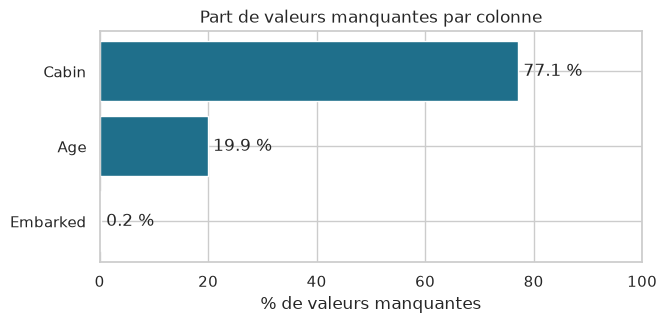

In [11]:
cols_manquantes = manquants.query("nb_manquants > 0")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(cols_manquantes.index, cols_manquantes["pct_manquants"], color="#1F6F8B")
ax.set_xlabel("% de valeurs manquantes")
ax.set_title("Part de valeurs manquantes par colonne")
ax.invert_yaxis()
for i, v in enumerate(cols_manquantes["pct_manquants"]):
    ax.text(v + 1, i, f"{v} %", va="center")
ax.set_xlim(0, 100)
plt.show()

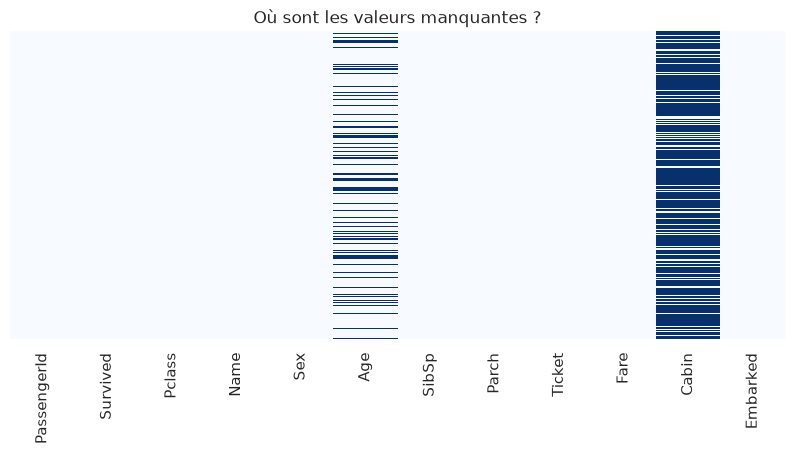

In [12]:
# Carte des manquants : chaque ligne du graphique = un passager, en clair = valeur manquante
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="Blues", ax=ax)
ax.set_title("Où sont les valeurs manquantes ?")
plt.show()

### 6.2 Pourquoi manquent-elles ? (MCAR / MAR / MNAR)

On compare les passagers **avec** et **sans** la valeur :

- si les deux groupes se ressemblent → le manque semble **aléatoire** (MCAR) ;
- s'ils diffèrent sur une autre variable → le manque **dépend de cette variable** (MAR) ;
- le MNAR ne se détecte pas ici : il faut raisonner avec le contexte.

In [13]:
def comparer_manquants(data, colonne):
    """Moyennes des variables numériques selon que `colonne` est manquante ou non."""
    groupes = data[colonne].isna().map({True: f"{colonne} manquant", False: f"{colonne} renseigné"})
    return data.select_dtypes(include="number").groupby(groupes).mean().round(2).T

for col in cols_manquantes.index:
    print(f"\n=== {col} ===")
    display(comparer_manquants(df, col))


=== Cabin ===


Cabin,Cabin manquant,Cabin renseigné
PassengerId,443.21,455.40
Survived,0.30,0.67
Pclass,2.64,1.20
Age,27.56,35.83
SibSp,0.55,0.44
Parch,0.37,0.44
Fare,19.16,76.14



=== Age ===


Age,Age manquant,Age renseigné
PassengerId,435.58,448.58
Survived,0.29,0.41
Pclass,2.60,2.24
Age,NaN,29.70
SibSp,0.56,0.51
Parch,0.18,0.43
Fare,22.16,34.69



=== Embarked ===


Embarked,Embarked manquant,Embarked renseigné
PassengerId,446.0,446.00
Survived,1.0,0.38
Pclass,1.0,2.31
Age,50.0,29.64
SibSp,0.0,0.52
Parch,0.0,0.38
Fare,80.0,32.10


### 6.3 Corrélation entre le fait de manquer et les autres variables

On transforme « la valeur manque » en une colonne 0/1, puis on la corrèle avec les autres variables numériques. Cela résume en un seul score (de −1 à 1) ce que montre le tableau précédent.

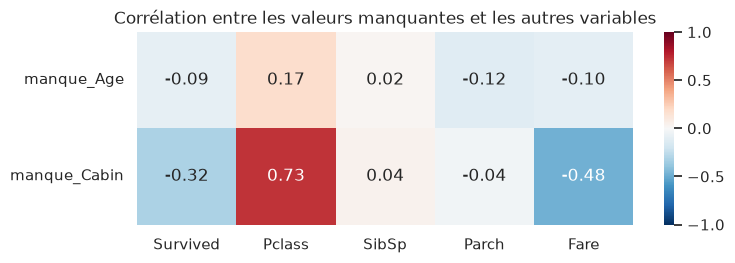

In [14]:
indicateurs = df[["Age", "Cabin"]].isna().astype(int).add_prefix("manque_")
autres = df.select_dtypes("number").drop(columns=["PassengerId", "Age"])

corr_manquants = pd.concat([indicateurs, autres], axis=1).corr().loc[indicateurs.columns, autres.columns]

fig, ax = plt.subplots(figsize=(8, 2.5))
sns.heatmap(corr_manquants, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Corrélation entre les valeurs manquantes et les autres variables")
plt.show()

**Mes observations :**

- **`Cabin` (77 % manquants)** : le manque n'est pas aléatoire. Il touche 98 % des passagers de 3e classe contre 19 % en 1re. Les passagers sans cabine renseignée ont payé moins cher (19 £ en moyenne contre 76 £) et ont moins survécu (30 % contre 67 %). La corrélation le confirme : 0,73 avec la classe et −0,48 avec le prix. **L'absence de cabine est donc une information en soi.**
- **`Age` (20 % manquants)** : le manque est plus fréquent en 3e classe (28 % contre 14 % en 1re et 6 % en 2e) et chez les passagers voyageant sans parents ni enfants. Il dépend donc d'autres variables (plutôt un cas **MAR**), mais le lien reste modéré (corrélation de 0,17 au plus, avec la classe). Une simple médiane globale ignorerait ces différences.
- **`Embarked` (2 manquants)** : deux passagères de 1re classe voyageant ensemble (même billet, même cabine). Le volume est trop faible pour analyser le mécanisme de manque, et l'impact sur l'analyse sera négligeable.

## 7. Statistiques descriptives

In [15]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [16]:
df.describe(exclude="number").T   # colonnes texte : nb de valeurs, distinctes, la plus fréquente

,count,unique,top,freq
Name,891,891,"Braund, Mr. Owen Harris",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,G6,4
Embarked,889,3,S,644


In [17]:
# Répartition des modalités pour les variables à faible cardinalité
for col in ["Pclass", "Sex", "SibSp", "Parch", "Embarked"]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- Pclass ---
Pclass
3    491
1    216
2    184
Name: count, dtype: int64

--- Sex ---
Sex
male      577
female    314
Name: count, dtype: int64

--- SibSp ---
SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64

--- Parch ---
Parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64

--- Embarked ---
Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64


**Mes observations :**

- 891 passagers, dont **65 % d'hommes** et **55 % en 3e classe**. La majorité a embarqué à Southampton (72 %).
- **Âge** : moyenne de 29,7 ans, médiane de 28 ans, de 5 mois à 80 ans. La distribution est assez symétrique.
- **`Fare`** : moyenne de 32 £ mais médiane de 14 £. La moyenne est tirée vers le haut par quelques billets très chers (jusqu'à 512 £). La distribution est très asymétrique.
- **`SibSp` et `Parch`** : la grande majorité voyage sans famille (68 % sans frère, sœur ni conjoint, 76 % sans parent ni enfant). Quelques familles nombreuses vont jusqu'à 8 frères et sœurs.
- **Surprise :** 15 billets à **0 £** (voir la section 10.2).

## 8. La variable cible : `Survived`

Avant tout modèle, on regarde l'**équilibre des classes**. Si une classe est très majoritaire, l'*accuracy* seule peut être trompeuse.

Survived
Décédé       61.6 %
Survivant    38.4 %
Name: proportion, dtype: str


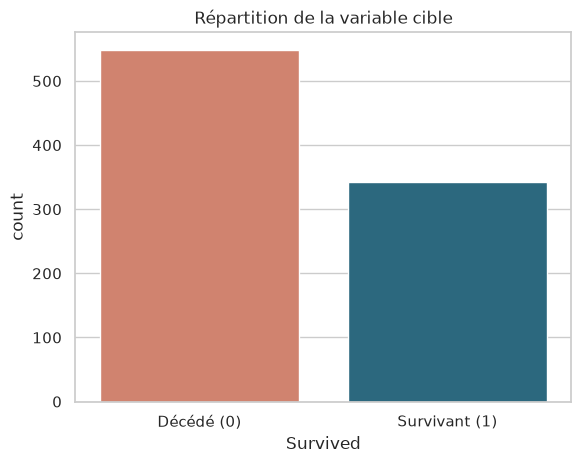

In [18]:
taux = df["Survived"].value_counts(normalize=True).rename({0: "Décédé", 1: "Survivant"}) * 100
print(taux.round(1).astype(str) + " %")

ax = sns.countplot(data=df, x="Survived", hue="Survived", palette=["#E07A5F", "#1F6F8B"], legend=False)
ax.set_xticks([0, 1], ["Décédé (0)", "Survivant (1)"])
ax.set_title("Répartition de la variable cible")
plt.show()

## 9. Distributions (analyse univariée)

### 9.1 Variables numériques continues

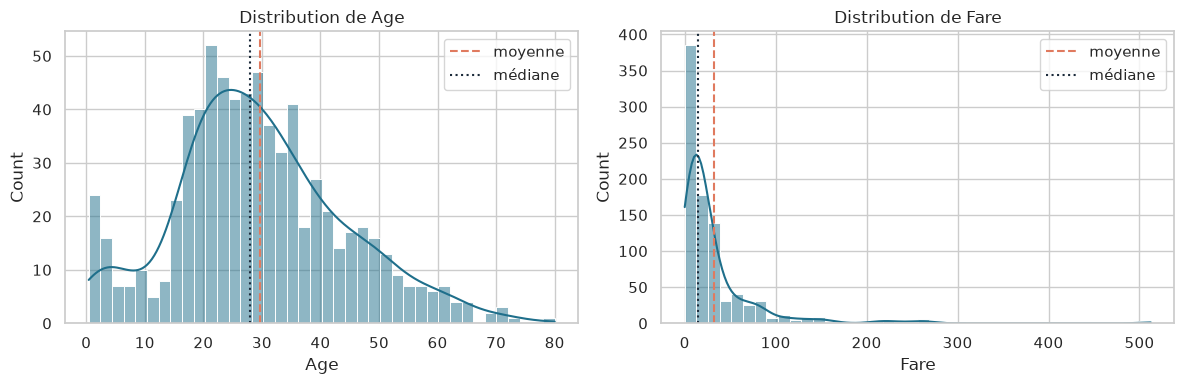

Asymétrie (skewness) :
Age     0.39
Fare    4.79
dtype: float64


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["Age", "Fare"]):
    sns.histplot(df[col].dropna(), bins=40, kde=True, ax=ax, color="#1F6F8B")
    ax.axvline(df[col].mean(), color="#E07A5F", linestyle="--", label="moyenne")
    ax.axvline(df[col].median(), color="#1B2A3A", linestyle=":", label="médiane")
    ax.set_title(f"Distribution de {col}")
    ax.legend()
plt.tight_layout()
plt.show()

print("Asymétrie (skewness) :")
print(df[["Age", "Fare"]].skew().round(2))

> Une asymétrie (*skewness*) nettement supérieure à 1 indique une distribution étirée vers la droite : quelques valeurs très grandes tirent la moyenne vers le haut.

### 9.2 Variables catégorielles et discrètes

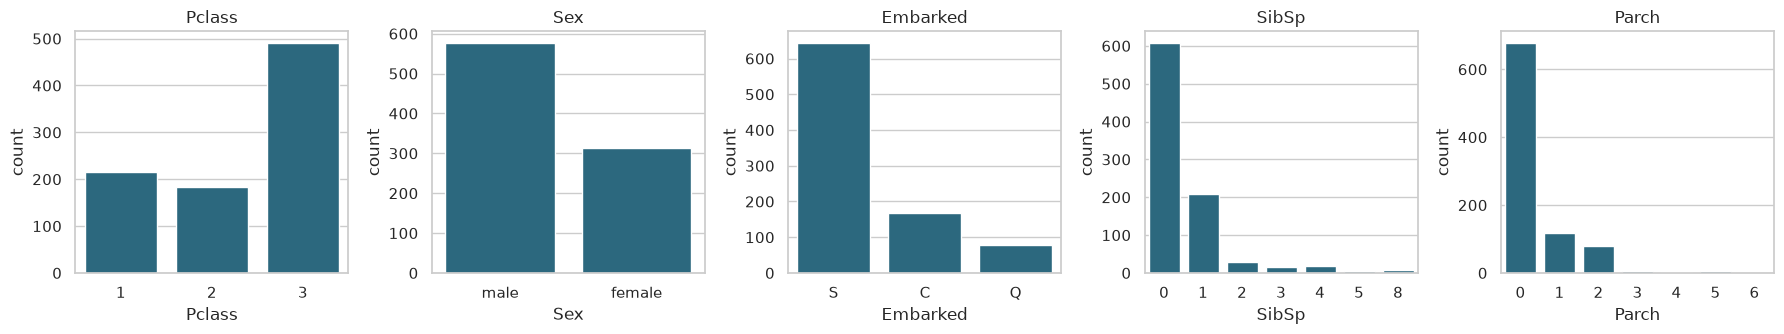

In [20]:
cols_cat = ["Pclass", "Sex", "Embarked", "SibSp", "Parch"]
fig, axes = plt.subplots(1, len(cols_cat), figsize=(18, 3.5))
for ax, col in zip(axes, cols_cat):
    sns.countplot(data=df, x=col, ax=ax, color="#1F6F8B")
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 9.3 Colonnes texte : y a-t-il de l'information cachée ?

Certaines colonnes texte ne sont pas exploitables telles quelles, mais peuvent contenir une information utile. On se contente ici de **regarder**.

In [21]:
df["Name"].head(10)

0                              Braund, Mr. Owen Harris
1    Cumings, Mrs. John Bradley (Florence Briggs Th...
2                               Heikkinen, Miss. Laina
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)
4                             Allen, Mr. William Henry
5                                     Moran, Mr. James
6                              McCarthy, Mr. Timothy J
7                       Palsson, Master. Gosta Leonard
8    Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)
9                  Nasser, Mrs. Nicholas (Adele Achem)
Name: Name, dtype: str

In [22]:
df["Ticket"].head(10)

0           A/5 21171
1            PC 17599
2    STON/O2. 3101282
3              113803
4              373450
5              330877
6               17463
7              349909
8              347742
9              237736
Name: Ticket, dtype: str

In [23]:
df["Cabin"].dropna().head(10)

1             C85
3            C123
6             E46
10             G6
11           C103
21            D56
23             A6
27    C23 C25 C27
31            B78
52            D33
Name: Cabin, dtype: str

### 9.4 Aperçu des titres contenus dans `Name`

On se contente de **compter** les titres (le texte entre la virgule et le point), sans créer de variable pour l'instant.

In [24]:
titres = df["Name"].str.extract(r",\s*([^\.]+)\.")[0]

df.assign(Titre=titres).groupby("Titre").agg(
    effectif=("Age", "size"),
    age_median=("Age", "median"),
    age_manquants=("Age", lambda s: s.isna().sum()),
    taux_survie=("Survived", "mean"),
).round(2).sort_values("effectif", ascending=False)

,effectif,age_median,age_manquants,taux_survie
Titre,,,,
Mr,517,30.0,119,0.16
Miss,182,21.0,36,0.70
Mrs,125,35.0,17,0.79
Master,40,3.5,4,0.57
Dr,7,46.5,1,0.43
Rev,6,46.5,0,0.00
Mlle,2,24.0,0,1.00
Major,2,48.5,0,0.50
Col,2,58.0,0,0.50


**Mes observations :**

- **`Name`** contient un **titre** (Mr, Mrs, Miss, Master…) qui renseigne sur le sexe, l'âge approximatif et parfois le statut social. 4 titres couvrent 97 % des passagers. Le titre donne une très bonne idée de l'âge : « Master » désigne les jeunes garçons (âge médian 3,5 ans), « Miss » des femmes plus jeunes que « Mrs ». C'est une **piste sérieuse pour imputer l'âge**. Les 13 titres rares (Dr, Rev, Col, Countess…) devront probablement être regroupés.
- **`Ticket`** : 681 valeurs distinctes pour 891 passagers. Certains billets sont **partagés** (familles ou groupes). Le format est hétérogène (préfixes comme `PC`, `CA.`, `LINE`). Peu exploitable tel quel.
- **`Cabin`** : la première lettre correspond au **pont** (A à G). Certains passagers ont plusieurs cabines (« C23 C25 C27 »). Exploitable, mais seulement sur 23 % des passagers.
- **`PassengerId`** : simple numéro de ligne, sans information.

## 10. Valeurs aberrantes

On utilise la **règle de l'IQR** : une valeur est considérée comme extrême si elle sort de l'intervalle [Q1 − 1,5 × IQR ; Q3 + 1,5 × IQR].

> Une valeur extrême n'est **pas forcément une erreur**. Il faut se demander si elle est plausible dans la réalité.

In [25]:
def resume_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    borne_basse, borne_haute = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    extremes = serie[(serie < borne_basse) | (serie > borne_haute)]
    return pd.Series({
        "borne_basse": round(borne_basse, 2),
        "borne_haute": round(borne_haute, 2),
        "nb_extremes": len(extremes),
        "pct_extremes": round(len(extremes) / serie.notna().sum() * 100, 1),
        "min": serie.min(),
        "max": serie.max(),
    })

df[["Age", "Fare", "SibSp", "Parch"]].apply(resume_iqr).T

,borne_basse,borne_haute,nb_extremes,pct_extremes,min,max
Age,-6.69,64.81,11.0,1.5,0.42,80.0000
Fare,-26.72,65.63,116.0,13.0,0.00,512.3292
SibSp,-1.50,2.50,46.0,5.2,0.00,8.0000
Parch,0.00,0.00,213.0,23.9,0.00,6.0000


> **Limite de la règle IQR :** sur une variable discrète presque toujours égale à 0 (comme `Parch`), Q1 = Q3 = 0, donc **toute** valeur non nulle est marquée « extrême ». La règle n'a pas de sens ici : il faut toujours interpréter le résultat.

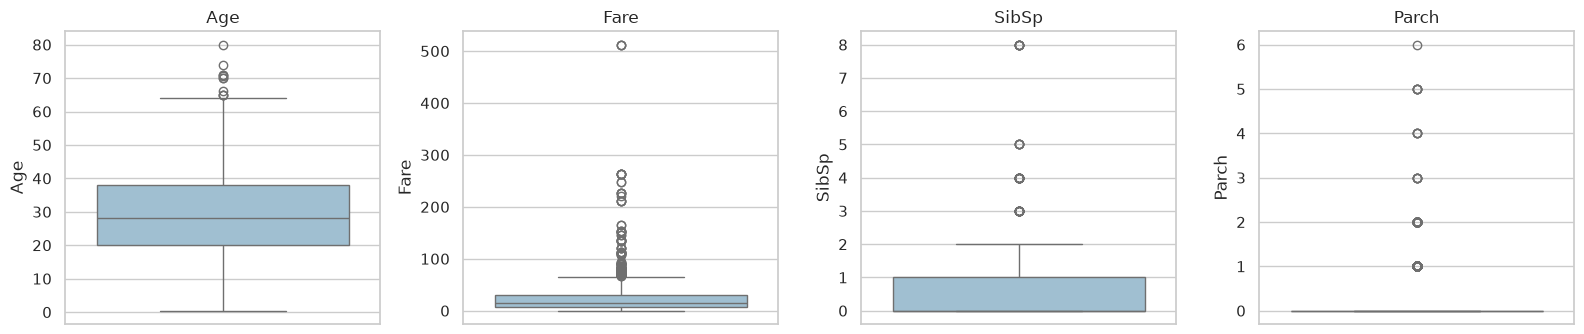

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, ["Age", "Fare", "SibSp", "Parch"]):
    sns.boxplot(y=df[col], ax=ax, color="#98C1D9")
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [27]:
# Les valeurs les plus élevées sont-elles plausibles ? On regarde les lignes concernées.
df.nlargest(5, "Fare")

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
258,259,1,1,"Ward, Miss. Anna",female,35.0,0,0,PC 17755,512.3292,NaN,C
679,680,1,1,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,0,1,PC 17755,512.3292,B51 B53 B55,C
737,738,1,1,"Lesurer, Mr. Gustave J",male,35.0,0,0,PC 17755,512.3292,B101,C
27,28,0,1,"Fortune, Mr. Charles Alexander",male,19.0,3,2,19950,263.0000,C23 C25 C27,S
88,89,1,1,"Fortune, Miss. Mabel Helen",female,23.0,3,2,19950,263.0000,C23 C25 C27,S


### 10.2 Les billets à 0 £

Un prix de 0 n'est pas détecté par la règle IQR, mais il est suspect : on regarde qui sont ces passagers.

In [28]:
billets_gratuits = df[df["Fare"] == 0]
print(f"{len(billets_gratuits)} billets à 0 £ — taux de survie : {billets_gratuits['Survived'].mean():.0%}")
billets_gratuits[["Name", "Pclass", "Sex", "Age", "Ticket", "Embarked", "Survived"]]

15 billets à 0 £ — taux de survie : 7%


,Name,Pclass,Sex,Age,Ticket,Embarked,Survived
179,"Leonard, Mr. Lionel",3,male,36.0,LINE,S,0
263,"Harrison, Mr. William",1,male,40.0,112059,S,0
271,"Tornquist, Mr. William Henry",3,male,25.0,LINE,S,1
277,"Parkes, Mr. Francis ""Frank""",2,male,NaN,239853,S,0
302,"Johnson, Mr. William Cahoone Jr",3,male,19.0,LINE,S,0
413,"Cunningham, Mr. Alfred Fleming",2,male,NaN,239853,S,0
466,"Campbell, Mr. William",2,male,NaN,239853,S,0
481,"Frost, Mr. Anthony Wood ""Archie""",2,male,NaN,239854,S,0
597,"Johnson, Mr. Alfred",3,male,49.0,LINE,S,0
633,"Parr, Mr. William Henry Marsh",1,male,NaN,112052,S,0


**Mes observations :**

- **`Fare`** : 13 % des valeurs sont au-dessus du seuil IQR. Ce sont des **billets réels** de 1re classe (512 £ pour la suite de la famille Cardeza), souvent achetés pour plusieurs personnes. Ce ne sont pas des erreurs, il ne faut pas les supprimer.
- **`Age`** : 11 valeurs au-delà de 65 ans, toutes plausibles (maximum 80 ans).
- **`SibSp` et `Parch`** : les valeurs élevées correspondent à de vraies familles nombreuses (par exemple la famille Sage, avec 8 frères et sœurs). La règle IQR n'est pas adaptée à ces variables presque toujours égales à 0.
- **Seule vraie anomalie : les 15 billets à 0 £.** Tous des hommes, tous embarqués à Southampton, répartis dans les 3 classes. Plusieurs billets portent la mention `LINE` ou des numéros consécutifs. Selon les sources historiques, il s'agirait de **membres du personnel** voyageant gratuitement (employés de compagnies maritimes, équipe du chantier naval). Ils ont survécu à 7 % seulement. Ce n'est pas une erreur de saisie mais un groupe particulier, à ne pas confondre avec des prix manquants.

## 11. Liens avec la survie (analyse bivariée)

### 11.1 Taux de survie par catégorie

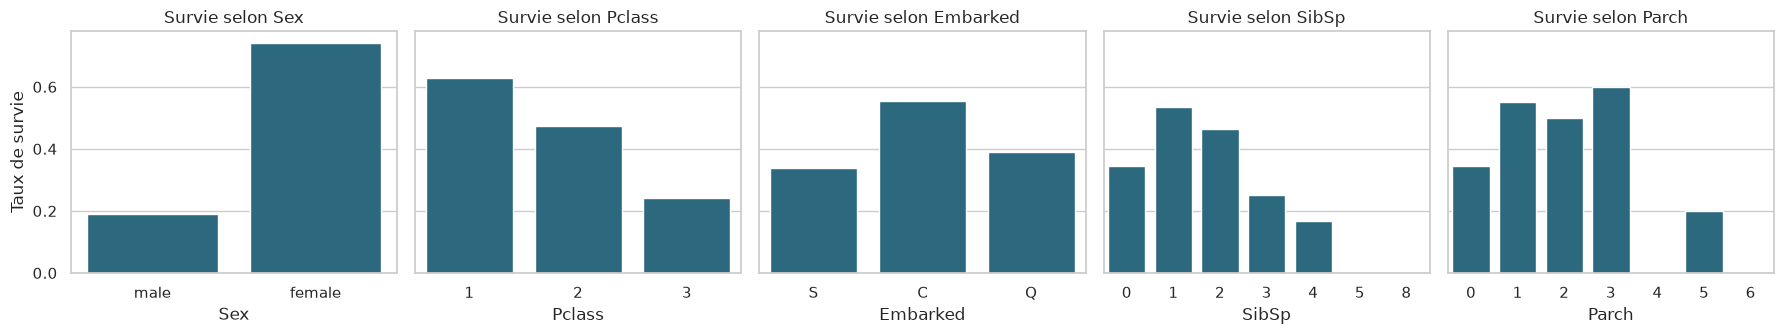

In [29]:
cols_cat = ["Sex", "Pclass", "Embarked", "SibSp", "Parch"]
fig, axes = plt.subplots(1, len(cols_cat), figsize=(18, 3.5), sharey=True)
for ax, col in zip(axes, cols_cat):
    sns.barplot(data=df, x=col, y="Survived", ax=ax, color="#1F6F8B", errorbar=None)
    ax.set_title(f"Survie selon {col}")
    ax.set_ylabel("Taux de survie")
plt.tight_layout()
plt.show()

In [30]:
for col in ["Sex", "Pclass", "Embarked"]:
    print(f"\n--- Taux de survie selon {col} ---")
    print((df.groupby(col)["Survived"].agg(["mean", "count"])
             .rename(columns={"mean": "taux_survie", "count": "effectif"})
             .round(2)))


--- Taux de survie selon Sex ---
        taux_survie  effectif
Sex                          
female         0.74       314
male           0.19       577

--- Taux de survie selon Pclass ---
        taux_survie  effectif
Pclass                       
1              0.63       216
2              0.47       184
3              0.24       491

--- Taux de survie selon Embarked ---
          taux_survie  effectif
Embarked                       
C                0.55       168
Q                0.39        77
S                0.34       644


In [31]:
# Croisement de deux variables : sexe × classe
pd.crosstab(df["Pclass"], df["Sex"], values=df["Survived"], aggfunc="mean").round(2)

Sex,female,male
Pclass,,
1,0.97,0.37
2,0.92,0.16
3,0.50,0.14


### 11.2 Variables continues selon la survie

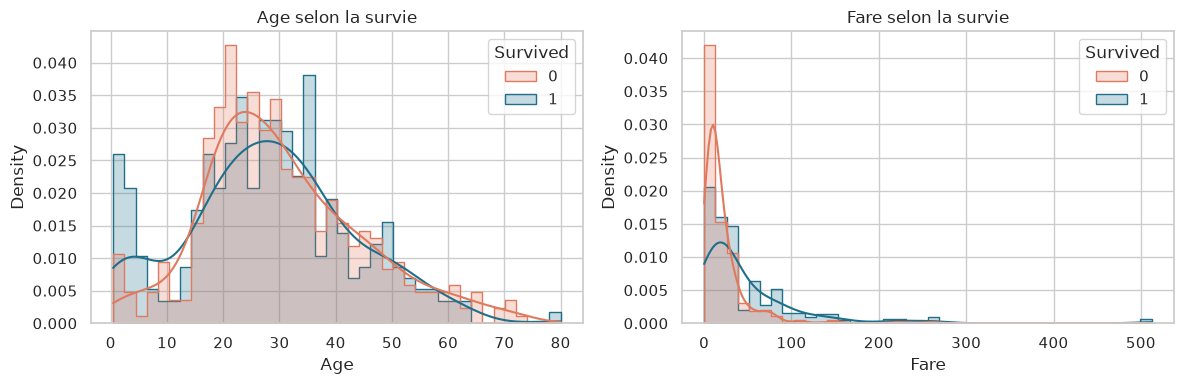

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["Age", "Fare"]):
    sns.histplot(data=df, x=col, hue="Survived", bins=40, kde=True, ax=ax,
                 palette=["#E07A5F", "#1F6F8B"], element="step", stat="density", common_norm=False)
    ax.set_title(f"{col} selon la survie")
plt.tight_layout()
plt.show()

### 11.3 Survie selon l'âge et le sexe

La corrélation entre l'âge et la survie est faible. On vérifie si l'effet de l'âge dépend du sexe, en découpant l'âge en tranches.

Sex,female,male
Age,,
"(-0.001, 12.0]",0.59,0.57
"(12.0, 18.0]",0.75,0.09
"(18.0, 30.0]",0.76,0.16
"(30.0, 45.0]",0.78,0.22
"(45.0, 60.0]",0.85,0.19
"(60.0, 80.0]",1.00,0.11


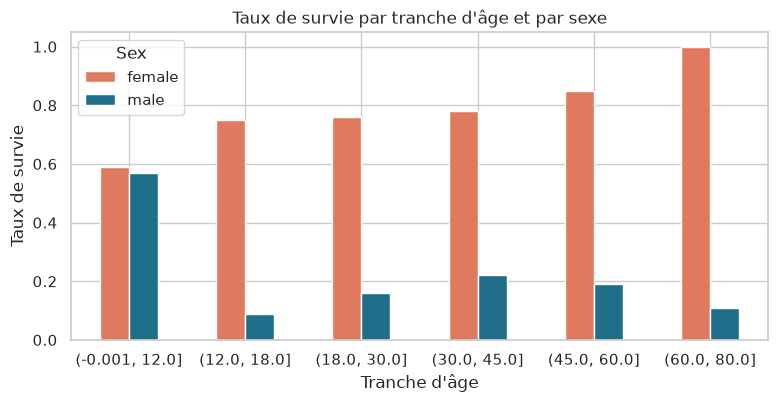

In [33]:
tranches = pd.cut(df["Age"], bins=[0, 12, 18, 30, 45, 60, 80], include_lowest=True)
survie_age_sexe = pd.crosstab(tranches, df["Sex"], values=df["Survived"], aggfunc="mean").round(2)
display(survie_age_sexe)

ax = survie_age_sexe.plot(kind="bar", color=["#E07A5F", "#1F6F8B"], figsize=(9, 4), rot=0)
ax.set_xlabel("Tranche d'âge")
ax.set_ylabel("Taux de survie")
ax.set_title("Taux de survie par tranche d'âge et par sexe")
plt.show()

**Mes observations :**

- **Le sexe est le facteur le plus marquant** : 74 % des femmes ont survécu, contre 19 % des hommes.
- **La classe compte aussi** : 63 % de survie en 1re classe, 47 % en 2e, 24 % en 3e.
- **Les deux se combinent** : 97 % des femmes de 1re classe ont survécu, contre 14 % des hommes de 3e.
- **L'âge joue surtout chez les garçons** : avant 12 ans, garçons et filles ont survécu presque autant (57 % et 59 %). Dès l'adolescence, les garçons tombent au niveau des hommes adultes (9 à 22 %). Le « femmes et enfants d'abord » se vérifie, et cela explique pourquoi la corrélation globale entre l'âge et la survie est faible (−0,08).
- **Port d'embarquement** : Cherbourg affiche 55 % de survie contre 34 % pour Southampton. C'est probablement un effet indirect : plus de passagers de 1re classe ont embarqué à Cherbourg. À vérifier.
- **Prix du billet** : la médiane est de 26 £ chez les survivants contre 10,5 £ chez les décédés. C'est cohérent avec l'effet de la classe.

## 12. Corrélations

La corrélation de Pearson mesure un lien **linéaire** entre deux variables numériques (de −1 à 1).

> Corrélation ≠ causalité. Et une corrélation proche de 0 n'exclut pas un lien non linéaire.

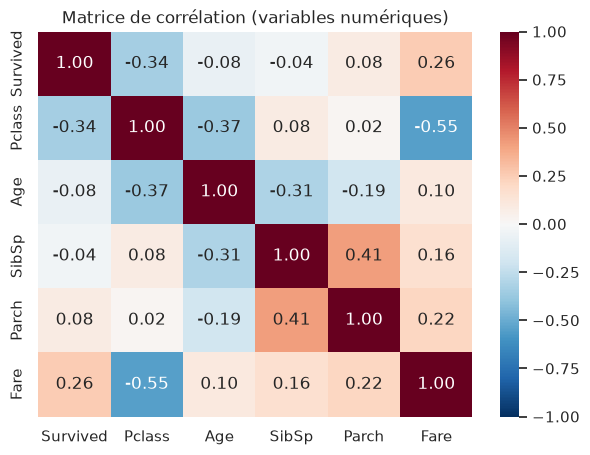

In [34]:
corr = df.select_dtypes(include="number").drop(columns="PassengerId").corr()

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Matrice de corrélation (variables numériques)")
plt.show()

In [35]:
corr["Survived"].drop("Survived").sort_values(key=abs, ascending=False)

Pclass   -0.338481
Fare      0.257307
Parch     0.081629
Age      -0.077221
SibSp    -0.035322
Name: Survived, dtype: float64

> `Sex` et `Embarked` n'apparaissent pas ici car ce sont encore du texte : ils seront intégrés après encodage.

## 13. Synthèse et hypothèses

### Problèmes de qualité repérés

| Colonne | Problème observé | Piste de traitement (à décider au nettoyage) |
|---|---|---|
| `Age` | 20 % de manquants, liés à la classe | Imputation tenant compte d'autres variables (classe, titre) |
| `Cabin` | 77 % de manquants, absence informative | Supprimer la colonne mais garder l'information « cabine connue ou non » |
| `Embarked` | 2 manquants | Imputation simple (valeur la plus fréquente) |
| `Fare` | Très asymétrique, 15 valeurs à 0 | Conserver les valeurs extrêmes, réfléchir au cas des billets à 0 |
| `Name` | Information cachée (titre) | Extraire le titre |
| `Sex`, `Embarked` | Texte | Encodage |
| `PassengerId`, `Ticket` | Pas d'information prédictive directe | Supprimer |

### Hypothèses à vérifier

1. Les femmes ont davantage survécu que les hommes (« les femmes d'abord »).
2. Plus la classe est élevée, plus les chances de survie sont grandes.
3. Les enfants ont été favorisés, mais surtout les garçons, qui sinon auraient suivi le sort des hommes.
4. Voyager seul ou en très grande famille réduit les chances de survie par rapport à une petite famille.
5. L'effet du port d'embarquement s'explique par la classe des passagers, pas par le port lui-même.